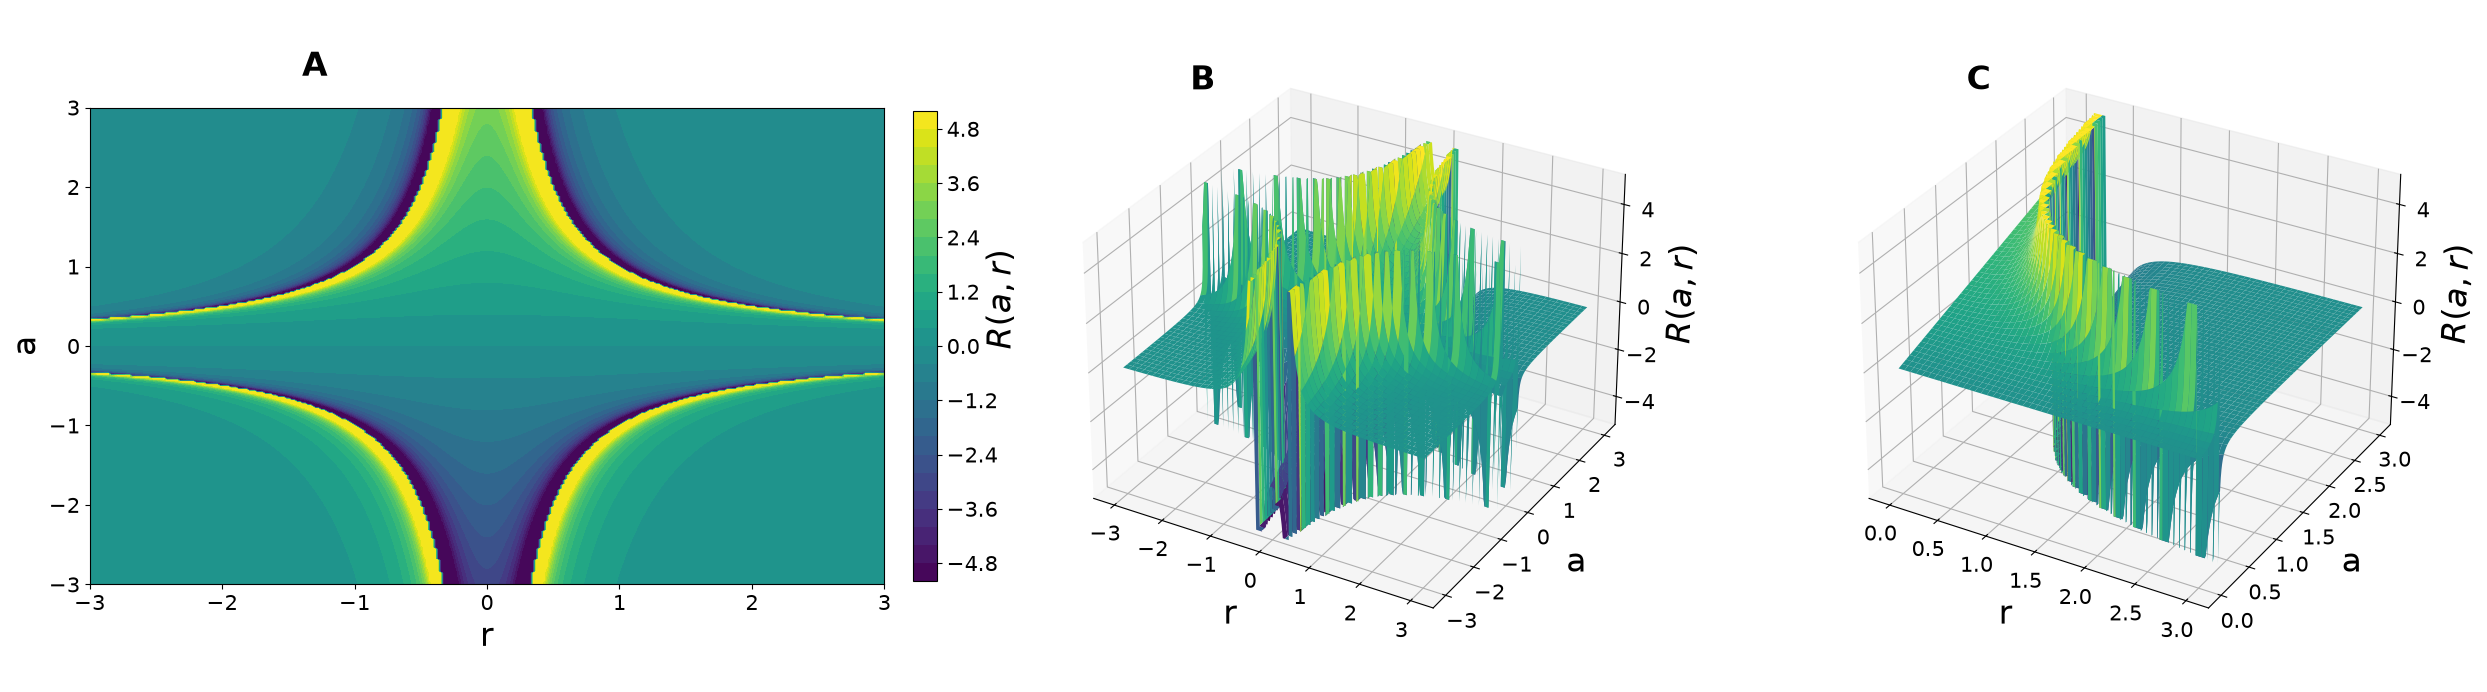

In [1]:
# MIT License
# Copyright (c) 2026 T.H.Günther, mail@gnthr.de

import numpy as np
import matplotlib.pyplot as plt

# Define L and arealradius R
L = -1
def R(r, a):
    return a / (1 + L*(a**2 * r**2))

# range of values / grid / function z(x,y)
r = np.linspace(-3, 3, 300)
a = np.linspace(-3, 3, 300)
x, y = np.meshgrid(r, a)
z_cut = np.clip(R(x, y), -5, 5)

# Grid for r>0, a>0
r_pos = np.linspace(0, 3, 300)
a_pos = np.linspace(0, 3, 300)
x_pos, y_pos = np.meshgrid(r_pos, a_pos)
z_pos = np.clip(R(x_pos, y_pos), -5, 5)

fs = 24
fs2 = 15

fig = plt.figure(figsize=(30, 8))

# Layout
gs = fig.add_gridspec(1, 3, left=0.04, right=0.88, bottom=0.08, top=0.92, wspace=-0.2)

# A) Contourplot
ax1 = fig.add_subplot(gs[0, 0])
contour = ax1.contourf(x, y, z_cut, levels=30, cmap='viridis')
ax1.set_xlabel('r', fontsize=fs)
ax1.set_ylabel('a', fontsize=fs)

ax1.set_box_aspect(0.6)

cbar = fig.colorbar(contour, ax=ax1, shrink=0.7, pad=0.03)
cbar.set_label('$ R(a,r) $', fontsize=fs , labelpad=-9, y=0.6)
cbar.ax.tick_params(labelsize=fs2)
ax1.tick_params(axis='both', labelsize=fs2) 



# B) 3D-Plot function
ax2 = fig.add_subplot(gs[0, 1], projection='3d')
ax2.plot_surface(x, y, z_cut, cmap='viridis', edgecolor='none')
ax2.set_xlabel('r', fontsize=fs, labelpad=15)
ax2.set_ylabel('a', fontsize=fs, labelpad=15)
ax2.set_zlabel('$ R(a,r) $', fontsize=fs, labelpad=10)
ax2.set_box_aspect(None, zoom=0.9)

ax2.tick_params(axis='both', labelsize=fs2) 
ax2.zaxis.set_tick_params(labelsize=fs2)

# C) 3D-Plot Areal Radius for r>0, a>0 
ax3 = fig.add_subplot(gs[0, 2], projection='3d')
ax3.plot_surface(x_pos, y_pos, z_pos, cmap='viridis', edgecolor='none')
ax3.set_xlabel('r', fontsize=fs , labelpad=15)
ax3.set_ylabel('a', fontsize=fs , labelpad=15)
ax3.set_zlabel('$ R(a,r) $', fontsize=fs, labelpad=10)
ax3.set_box_aspect(None, zoom=0.9)

ax3.tick_params(axis='both', labelsize=fs2) 
ax3.zaxis.set_tick_params(labelsize=fs2)


def panel_label(ax, label, x=-0.1, y=1.05, fs=24):
    if hasattr(ax, 'text2D'):          # 3D-Achse
        ax.text2D(x, y, label, transform=ax.transAxes,
                  fontsize=fs, fontweight='bold', va='bottom', ha='right')
    else:                              # normale 2D-Achse
        ax.text(x, y, label, transform=ax.transAxes,
                fontsize=fs, fontweight='bold', va='bottom', ha='right')

panel_label(ax1, 'A', x=0.3, y=1.05)
panel_label(ax2, 'B', x=0.3, y=0.87)
panel_label(ax3, 'C', x=0.3, y=0.87)

plt.savefig("NL_ArealRadius_3d.png", dpi=300, bbox_inches="tight")

plt.show()